# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [41]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [42]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [43]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [44]:
df = pd.read_csv(PLIK_LODZ, sep=";")
display(df.head())
print(df.info())

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   name     65 non-null     object
 1   rok      65 non-null     int64 
 2   wartość  65 non-null     int64 
 3   zmienna  65 non-null     object
dtypes: int64(2), object(2)
memory usage: 2.2+ KB
None


In [45]:
df = pd.read_csv(PLIK_LODZ, sep=";")
display(df.head())
print(df.info())

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   name     65 non-null     object
 1   rok      65 non-null     int64 
 2   wartość  65 non-null     int64 
 3   zmienna  65 non-null     object
dtypes: int64(2), object(2)
memory usage: 2.2+ KB
None


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* …

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [46]:
print(df["zmienna"].value_counts())
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


In [47]:
print(df["zmienna"].value_counts())
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [48]:
roznica = (szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"]
roznica

,0
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


In [49]:
roznica = (szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"]
roznica

,0
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [50]:
display(szeroka.describe())
zmiana_procentowa = ((szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012]) * 100
display(zmiana_procentowa)
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


,0
zmienna,
absolwenci ogółem,-41.29
kobiety,-30.22
mężczyźni,-29.14
ogółem,-29.79
uczelnie,-31.82


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


In [51]:
display(szeroka.describe())

zmiana_procentowa = ((szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012]) * 100
display(zmiana_procentowa)

szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka

zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
count,13.00,13.00,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54,0.60,3689.47
std,3522.40,5391.05,3524.63,8900.65,2.44,0.00,306.77
min,14082.00,38146.00,25710.00,64272.00,15.00,0.59,3273.59
25%,14756.00,39170.00,26049.00,65297.00,18.00,0.60,3507.65
50%,17046.00,39958.00,26297.00,66002.00,20.00,0.60,3635.86
75%,19835.00,45584.00,30769.00,76353.00,22.00,0.60,3841.00
max,24825.00,55265.00,36281.00,91546.00,23.00,0.61,4284.80


,0
zmienna,
absolwenci ogółem,-41.29
kobiety,-30.22
mężczyźni,-29.14
ogółem,-29.79
uczelnie,-31.82
udzial_kobiet,-0.61
studenci_na_uczelnie,2.97


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

In [52]:
axes[0].plot(szeroka.index, szeroka["kobiety"], label="Kobiety", marker="o")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], label="Mężczyźni", marker="s")
axes[0].set_title("Liczba studentów")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(szeroka.index, szeroka["uczelnie"], color="green", marker="d")
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba placówek")
axes[1].grid(True)
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], color="purple", marker="x")
axes[2].set_title("Udział kobiet")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział")
axes[2].set_ylim(0, 1)
axes[2].grid(True)

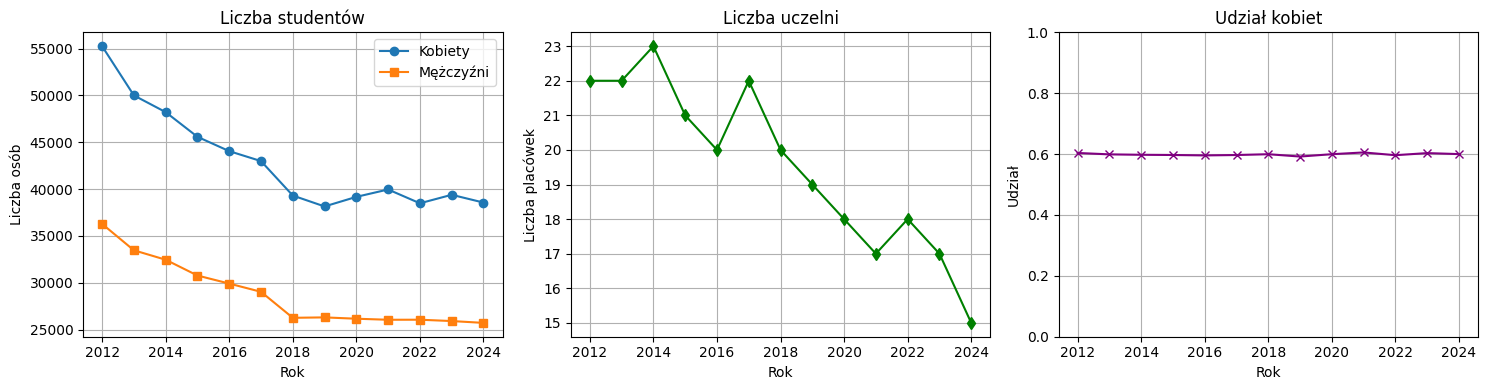

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(szeroka.index, szeroka["kobiety"], label="Kobiety", marker="o")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], label="Mężczyźni", marker="s")
axes[0].set_title("Liczba studentów")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(szeroka.index, szeroka["uczelnie"], color="green", marker="d")
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba placówek")
axes[1].grid(True)

axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], color="purple", marker="x")
axes[2].set_title("Udział kobiet")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział")
axes[2].set_ylim(0, 1)
axes[2].grid(True)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* …

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** … · **link:** … · **data pobrania:** …

In [54]:
import urllib.request
URL_WYPADKI = "https://otwarte.miasto.lodz.pl/dataset/6fb1da80-8742-49df-b45d-752940251781/resource/e387c936-e822-4df4-a827-8178d8a7ff21/download/zdarzenia-drogowe-wypadki-i-kolizje-w-lodzi-w-podziale-na-lata-2015-2023.csv"
PLIK_WYPADKI = "wypadki_drogowe.csv"
try:
    urllib.request.urlretrieve(URL_WYPADKI, PLIK_WYPADKI)
except Exception:
    pass
df_wypadki = pd.read_csv(PLIK_WYPADKI, sep=";")
display(df_wypadki.head())
print(df_wypadki.info())
print(df_wypadki.isna().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'wypadki_drogowe.csv'

In [ ]:
print(df_wypadki["zmienna"].value_counts())
wypadki_szeroka = df_wypadki.pivot(index="rok", columns="zmienna", values="wartość")
display(wypadki_szeroka.describe())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(wypadki_szeroka.index, wypadki_szeroka["wypadki"], marker="o", label="Wypadki", color="red")
ax.plot(wypadki_szeroka.index, wypadki_szeroka["kolizje"], marker="s", label="Kolizje", color="blue")
ax.set_title("Zdarzenia drogowe w Łodzi (2015-2023)")
ax.set_xlabel("Rok")
ax.set_ylabel("Liczba zdarzeń")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

✍️ **Wnioski:** …

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [ ]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* …

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [ ]:
zle_bmi = ~pacjenci["bmi"].between(10, 60) & pacjenci["bmi"].notna()
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800) & pacjenci["avg_glucose_level"].notna()
zly_wiek = ~pacjenci["age"].between(0, 120) & pacjenci["age"].notna()
print(zle_bmi.sum())
print(zla_glukoza.sum())
print(zly_wiek.sum())
print((zle_bmi | zla_glukoza | zly_wiek).sum())
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

In [ ]:
zle_bmi = ~pacjenci["bmi"].between(10, 60) & pacjenci["bmi"].notna()
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800) & pacjenci["avg_glucose_level"].notna()
zly_wiek = ~pacjenci["age"].between(0, 120) & pacjenci["age"].notna()
print(zle_bmi.sum())
print(zla_glukoza.sum())
print(zly_wiek.sum())
print((zle_bmi | zla_glukoza | zly_wiek).sum())
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 4), layout=(1, 3))
plt.tight_layout()
plt.show()

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

In [ ]:
axes[0].boxplot(pacjenci["bmi"].dropna(), vert=False)
axes[0].set_title("Wykres pudełkowy BMI")
axes[0].set_xlabel("BMI")
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), vert=False)
axes[1].set_title("Wykres pudełkowy poziomu glukozy")
axes[1].set_xlabel("Średni poziom glukozy [mg/dl]")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].boxplot(pacjenci["bmi"].dropna(), vert=False)
axes[0].set_title("Wykres pudełkowy BMI")
axes[0].set_xlabel("BMI")
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), vert=False)
axes[1].set_title("Wykres pudełkowy poziomu glukozy")
axes[1].set_xlabel("Średni poziom glukozy [mg/dl]")
plt.tight_layout()
plt.show()

In [ ]:
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5)
axes[0].set_title("Wiek vs Glukoza")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Średni poziom glukozy [mg/dl]")
axes[1].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5, color="orange")
axes[1].set_title("Wiek vs BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5)
axes[0].set_title("Wiek vs Glukoza")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Średni poziom glukozy [mg/dl]")
axes[1].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5, color="orange")
axes[1].set_title("Wiek vs BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI")
plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:* …

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [ ]:
def maska_iqr(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    res = 0.6745 * (s - med) / mad
    return res.abs() > prog

In [ ]:
def maska_iqr(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > prog

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    res = 0.6745 * (s - med) / mad
    return res.abs() > prog

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [ ]:
metody = {
    "IQR 1.5": lambda s: maska_iqr(s, 1.5).sum(),
    "IQR 3": lambda s: maska_iqr(s, 3.0).sum(),
    "z-score": lambda s: maska_z(s, 3).sum(),
    "MAD": lambda s: maska_mad(s, 3.5).sum(),
    "skew": lambda s: s.skew()
}
porownanie = pd.DataFrame(index=LICZBOWE, columns=metody.keys())
for col in LICZBOWE:
    for met_name, met_func in metody.items():
        porownanie.loc[col, met_name] = met_func(pacjenci[col])
porownanie

In [ ]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
metody = {
    "IQR 1.5": lambda s: maska_iqr(s, 1.5).sum(),
    "IQR 3": lambda s: maska_iqr(s, 3.0).sum(),
    "z-score": lambda s: maska_z(s, 3).sum(),
    "MAD": lambda s: maska_mad(s, 3.5).sum(),
    "skew": lambda s: s.skew()
}
porownanie = pd.DataFrame(index=LICZBOWE, columns=metody.keys())
for col in LICZBOWE:
    for met_name, met_func in metody.items():
        porownanie.loc[col, met_name] = met_func(pacjenci[col])
display(porownanie)

✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* …

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

In [ ]:
odstajace_glukoza = maska_iqr(pacjenci["avg_glucose_level"], 1.5)
liczba_odstajacych = odstajace_glukoza.sum()
q1 = pacjenci["avg_glucose_level"].quantile(0.25)
q3 = pacjenci["avg_glucose_level"].quantile(0.75)
granica = q3 + 1.5 * (q3 - q1)
plt.figure(figsize=(10, 6))
plt.scatter(pacjenci.loc[~odstajace_glukoza, "age"], pacjenci.loc[~odstajace_glukoza, "avg_glucose_level"], alpha=0.5, label="Normalne")
plt.scatter(pacjenci.loc[odstajace_glukoza, "age"], pacjenci.loc[odstajace_glukoza, "avg_glucose_level"], alpha=0.8, color="red", label=f"Odstające")
plt.axhline(granica, color="red", linestyle="--")
plt.title("Wiek vs Glukoza z zaznaczonymi wartościami odstającymi")
plt.xlabel("Wiek")
plt.ylabel("Średni poziom glukozy")
plt.legend()
plt.show()

In [ ]:
odstajace_glukoza = maska_iqr(pacjenci["avg_glucose_level"], 1.5)
liczba_odstajacych = odstajace_glukoza.sum()
q1 = pacjenci["avg_glucose_level"].quantile(0.25)
q3 = pacjenci["avg_glucose_level"].quantile(0.75)
granica = q3 + 1.5 * (q3 - q1)
plt.figure(figsize=(10, 6))
plt.scatter(pacjenci.loc[~odstajace_glukoza, "age"], pacjenci.loc[~odstajace_glukoza, "avg_glucose_level"], alpha=0.5, label="Normalne")
plt.scatter(pacjenci.loc[odstajace_glukoza, "age"], pacjenci.loc[odstajace_glukoza, "avg_glucose_level"], alpha=0.8, color="red", label=f"Odstające (N={liczba_odstajacych})")
plt.axhline(granica, color="red", linestyle="--")
plt.title("Wiek vs Glukoza z zaznaczonymi wartościami odstającymi")
plt.xlabel("Wiek")
plt.ylabel("Średni poziom glukozy")
plt.legend()
plt.show()

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

In [ ]:
glukoza_out = maska_iqr(pacjenci["avg_glucose_level"], 1.5)
print(pacjenci.loc[glukoza_out, "stroke"].mean())
print(pacjenci.loc[~glukoza_out, "stroke"].mean())
pacjenci.boxplot(column="avg_glucose_level", by="stroke", figsize=(8, 6))
plt.title("Rozkład glukozy w podziale na wystąpienie udaru")
plt.suptitle("")
plt.ylabel("Średnia glukoza")
plt.show()

In [ ]:
glukoza_out = maska_iqr(pacjenci["avg_glucose_level"], 1.5)
print(pacjenci.loc[glukoza_out, "stroke"].mean())
print(pacjenci.loc[~glukoza_out, "stroke"].mean())
pacjenci.boxplot(column="avg_glucose_level", by="stroke", figsize=(8, 6))
plt.title("Rozkład glukozy w podziale na wystąpienie udaru")
plt.suptitle("")
plt.ylabel("Średnia glukoza")
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* …

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [ ]:
tabela = pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])
display(tabela)
dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "Govt_job")
pacjenci_nielogiczni = pacjenci[dziecko_pali | maluch_student]
display(pacjenci_nielogiczni)

In [ ]:
tabela = pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])
display(tabela)
dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "Govt_job")
pacjenci_nielogiczni = pacjenci[dziecko_pali | maluch_student]
display(pacjenci_nielogiczni)

✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* …

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [ ]:
from scipy.stats import chi2
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)
odstajace_count = (d2 > prog).sum()
print(prog)
print(odstajace_count)
if odstajace_count > 0:
    wplyw = (Z.loc[d2 > prog] ** 2).idxmax(axis=1)
    print(wplyw.value_counts())

In [ ]:
from scipy.stats import chi2
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=3)
odstajace_count = (d2 > prog).sum()
print(prog)
print(odstajace_count)
if odstajace_count > 0:
    wplyw = (Z.loc[d2 > prog] ** 2).idxmax(axis=1)
    print(wplyw.value_counts())

Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

In [ ]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajace_log_count = (d2_log > prog).sum()
print(odstajace_log_count)
odstajace_idx = d2_log > prog
plt.figure(figsize=(10, 6))
plt.scatter(X.loc[~odstajace_idx, "bmi"], X.loc[~odstajace_idx, "avg_glucose_level"], alpha=0.5)
plt.scatter(X.loc[odstajace_idx, "bmi"], X.loc[odstajace_idx, "avg_glucose_level"], color="red", alpha=0.8)
plt.title("BMI vs Glukoza po transformacji logarytmicznej")
plt.xlabel("BMI")
plt.ylabel("Średni poziom glukozy")
plt.show()

In [ ]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajace_log_count = (d2_log > prog).sum()
print(odstajace_log_count)
odstajace_idx = d2_log > prog
plt.figure(figsize=(10, 6))
plt.scatter(X.loc[~odstajace_idx, "bmi"], X.loc[~odstajace_idx, "avg_glucose_level"], alpha=0.5)
plt.scatter(X.loc[odstajace_idx, "bmi"], X.loc[odstajace_idx, "avg_glucose_level"], color="red", alpha=0.8)
plt.title("BMI vs Glukoza po transformacji logarytmicznej")
plt.xlabel("BMI")
plt.ylabel("Średni poziom glukozy")
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* …

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [ ]:
# TODO (dla chętnych)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [ ]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = (zle_bmi | zla_glukoza | zly_wiek)
flagi["glukoza_iqr"] = maska_iqr(oryginal["avg_glucose_level"], 1.5)
flagi["nielogiczna_kategoria"] = (dziecko_pali | maluch_student)
odstajace_d2_map = (d2_log > prog)
flagi["odlegly_od_srodka"] = flagi.index.map(odstajace_d2_map).fillna(False).astype(bool)
display(flagi.sum())
print(flagi.any(axis=1).sum())

In [ ]:
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = (zle_bmi | zla_glukoza | zly_wiek)
flagi["glukoza_iqr"] = maska_iqr(oryginal["avg_glucose_level"], 1.5)
flagi["nielogiczna_kategoria"] = (dziecko_pali | maluch_student)
odstajace_d2_map = (d2_log > prog)
flagi["odlegly_od_srodka"] = flagi.index.map(odstajace_d2_map).fillna(False).astype(bool)
display(flagi.sum())
print(flagi.any(axis=1).sum())

✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | … | … |
| wysoka glukoza (IQR) | … | … |
| nielogiczne kategorie | … | … |
| odlegli od środka | … | … |